# Quantum Metal A.5 — launch-video chip: four-qubit ring with charge lines and readouts (Quantcore PDK rebuild)

**What the chip is.** The chip of the Qiskit Metal launch video,
`docs/circuit-examples/full-design-flow-examples/A.5-Launch-video-example.ipynb` (first video, the chip design; the
second video renders only the qubit core to HFSS; © IBM / Qiskit Metal contributors, Apache-2.0,
<https://github.com/qiskit-community/qiskit-metal>; spec `docs/designs/metal/A5_launch_video.md`): four
`TransmonPocket`s (pads 425 µm, pocket 650 µm, three connection pads each) in a ring at (±2.42, 0) and (0, ±0.95) mm,
joined by four λ/2 buses (5.6 / 5.7 mm). Each qubit has a λ/2 readout to a `LaunchpadWirebondCoupled` (5.5 mm
east / west, 13.0 mm south / north) and a charge line from a corner `LaunchpadWirebond` to an `OpenToGround` just
outside its pocket. All lines are 15/9 µm CPW (the tutorial sets the design variables `cpw_width` / `cpw_gap`). We
distribute the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the Metal
components are drawn through the `metal:<Class>` wrapper with the tutorial's options; the chip, the stack, the
junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal tutorial | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 9 × 6 mm centred on (0, 0) (the pads overhang it to 9 × 6.2 mm) | the 9 × 6.2 mm area grown by 0.6 mm per side (`box=(-600, -700, 9600, 6700)`: the corner pads clear the PDK marker areas), shifted by (+4.5, +3) mm, with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | 4 charge-line `LaunchpadWirebond`s, 4 readout `LaunchpadWirebondCoupled`s (outer edge 628–830 µm from the grown die edge) | the same pads, moved to **100 µm** (`frame.pad_edge`) from the die edge (PDK pad rule) |
| junctions | `Fake_Junctions` GDS (no value; the pre-rebuild build assumed 10 nH) | Quantcore Nb/AlOx/Nb trilayer junctions, PDK nominal 0.5 × 0.6 µm (R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF) |
| cheese | Metal's GDS cheese (exported with the renderer defaults: 25 µm squares every 100 µm, 25 µm buffer) | the original's Metal rule, drawn by the build (chip `cheese` = `metal_cheese_rule()`) |
| routes | `RouteMeander` buses 5.6 / 5.7 mm and readouts 5.5 / 13.0 mm, `RouteAnchors` charge lines | qcc meanders of the same lengths on the same pins, the charge lines through the same anchors |
| placement | as drawn | content centred in the die |

**Kept exactly:** every component with the tutorial's options, positions and orientations (connection pads `a` / `b`
/ `c` with their `loc_W` / `loc_H` and pad sizes, the `OpenToGround`s, the 8 launchpads with `lead_length` 0 and
their positions along the edges); every route's end pins and total length (buses 5600 / 5700 µm, readouts 5500 /
13 000 µm); the four charge lines through Metal's `RouteAnchors` anchors.

**Substituted / simplified:**
- The tutorial passes `cpw_width` / `cpw_gap` to the launchpads, which today's Metal ignores (its options are
  `trace_width` / `trace_gap`, defaulting to the same design variables); the rebuild sets `trace_width` 15,
  `trace_gap` 9 µm, which is what Metal draws.
- The qcc router puts each meander on one straight segment, symmetric about it (Metal shifts its meanders sideways
  with `asymmetry` ±140 µm and flips the lead direction): the readouts get waypoints that keep them clear of the
  charge lines, and the four ring buses use a 50 µm fillet (Metal 90 µm) so their two meander rows fit in the
  400 µm between the connection pads. Same end points and lengths, different footprints.

**Charge lines:** each `OpenToGround` sits on its pocket's symmetry axis, 136 µm beyond the pad ends and 23.5 µm
outside the pocket; it couples equally to both pads, so it hardly drives the qubit mode. No drive capacitance is
declared; the `Q<k>_read` C-matrix jobs include the charge-line ends.

The notebook goes step by step: PDK → die → pads → components → routes → centring → DRC → netlist → LOM →
FEM job → results back → one change re-simulated → fab export → snapshots → summary.

## 1 · Setup

The imports, the output folder and the `LIVE` switch: with KLayout open (the default), every step below is pushed to
the KLayout window as you run it; with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common`
holds the small helpers the design notebooks share (tables, snapshots, the PDK placement and fab helpers).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement and fab helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots

## 2 · The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the grown 10.2 × 7.4 mm box gets the QCT frame; the eight launchpads go 100 µm from their edges; the four qubits get the PDK nominal trilayer junction; the cheese is the original's (Metal's GDS cheese), drawn by the build instead of the PDK band.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm). The source's launchpads overhang its
9 × 6 mm chip by 77 µm, so the source area is taken as 9 × 6.2 mm, and it is grown by 0.6 mm per side so the corner
charge-line pads stay clear of the PDK marker areas. The PDK draws the **QCT frame** on it: L dicing markers in the
four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary (100/0) and the device
ID `name_chip` on a free edge (optional: no free edge, no ID). Metal centres its chip on (0, 0); `P(x, y)` shifts a
Metal position by half the chip, (+4500, +3000) µm.

**Cheese: the original's.** The source exports its GDS with Metal's cheese on (step 14), so the original's cheese wins over the PDK band: `chip={"cheese": metal_cheese_rule()}` hands the build Metal's rule (25 µm squares every 100 µm, 25 µm clear of every etched shape, none within 200 µm of the die edge), and the build draws it instead of the band (`_common.metal_cheese_rule`).

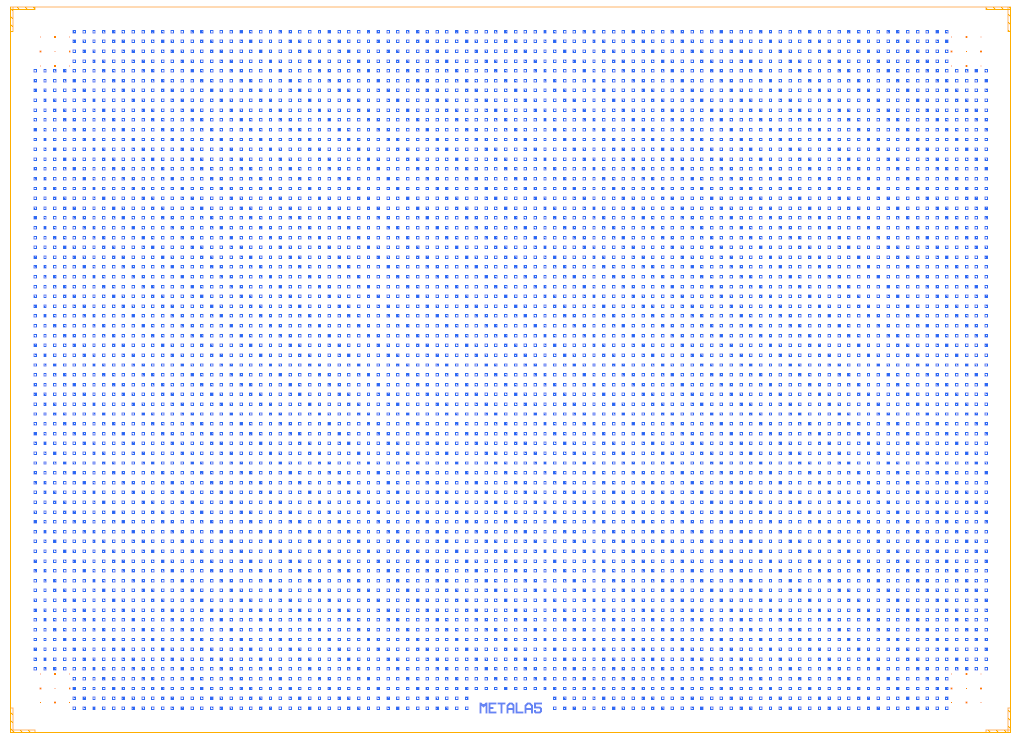

WindowsPath('examples/designs/metal/a5_launch_video_step_die.png')

In [4]:
d = Designer("a5_launch_video", box=(-600, -700, 9600, 6700), chip={"name_chip": "MetalA5", "cheese": metal_cheese_rule()},
             live=LIVE)
X0, Y0 = 4500, 3000                              # Metal's 9 × 6 mm DesignPlanar chip is centred on (0, 0)
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
CPW = dict(a=15, b=9)                            # design.variables cpw_width / cpw_gap
LP = dict(trace_width=15, trace_gap=9)           # launchpad traces (what Metal draws, see above)
R = 90                                           # Metal fillet
rebuild(d)                                       # build the empty die (a no-op when LIVE: it is already built)
snap(d, OUT / "a5_launch_video_step_die.png", size=(1020, 740), width=450)

## 4 · Pads: the PDK pad rule

The tutorial places four charge-line `LaunchpadWirebond`s near the corners (two on the north edge, two on the south)
and four readout `LaunchpadWirebondCoupled`s (east, west, south, north), all with `lead_length` 0. On the grown die
their outer edges sit 628–830 µm from the die edge. In the Quantcore PDK the outer edge of every bond pad's etch sits
**`frame.pad_edge` = 100 µm from the die edge**, whatever the source did: the last item of each tuple below is
the edge, and `edge=` slides the pad perpendicular to it until it is there. Its position along the edge is kept, so
the charge lines and readouts, which leave each pad along its axis, only get longer (the meanders keep their total
length and absorb it). The table measures it on the built layout.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P1_C | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| P2_C | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| P3_C | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| P4_C | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| P1_Q | `metal:LaunchpadWirebondCoupled` | e | 100.0 | ✓ |
| P2_Q | `metal:LaunchpadWirebondCoupled` | s | 100.0 | ✓ |
| P3_Q | `metal:LaunchpadWirebondCoupled` | w | 100.0 | ✓ |
| P4_Q | `metal:LaunchpadWirebondCoupled` | n | 100.0 | ✓ |

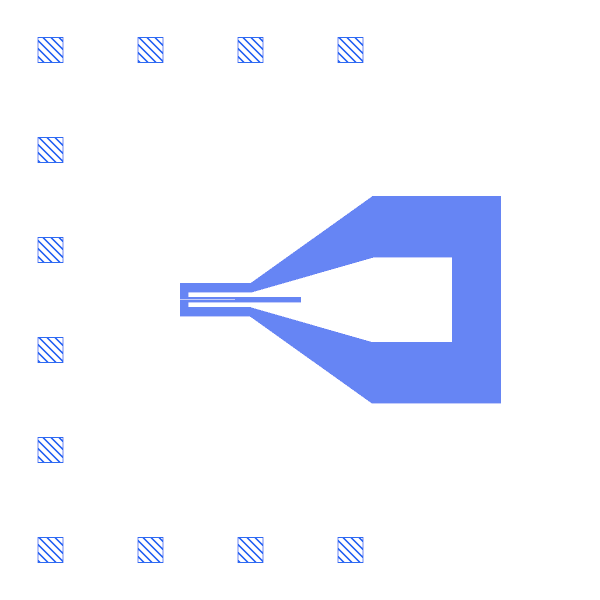

WindowsPath('examples/designs/metal/a5_launch_video_step_pads.png')

In [5]:
with d.batch():
    pc = {k: d.add(f"P{k}_C", "metal:LaunchpadWirebond", at=P(x, y), rot=r, lead_length=0, edge=e, **LP)
          for k, x, y, r, e in ((1, 4000, 2812, 270, "n"), (2, 4000, -2812, 90, "s"), (3, -4000, -2812, 90, "s"),
                                (4, -4000, 2812, 270, "n"))}
    pq = {k: d.add(f"P{k}_Q", "metal:LaunchpadWirebondCoupled", at=P(x, y), rot=r, lead_length=0, edge=e, **LP)
          for k, x, y, r, e in ((1, 4020, 0, 180, "e"), (2, -990, -2812, 90, "s"), (3, -4020, 0, 0, "w"),
                                (4, 990, 2812, 270, "n"))}
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "P1_Q.tie")
snap(d, OUT / "a5_launch_video_step_pads.png", box=(9000, py - 300, 9600, py + 300), size=(600, 600), width=300)

## 5 · Components: the four qubits and the charge-line ends

**The qubits.** `metal:TransmonPocket` is Metal's pocket transmon drawn by the wrapper with the tutorial's options:
two 425 µm pads in a 650 µm pocket and three connection pads — `a` (200 µm wide, to the readout), `b` (30 µm high) and
`c` (50 µm high) to the two ring buses. The different `b` / `c` pad heights detune each bus-coupled pair (30 µm pad at
one qubit, 50 µm at the other), so the pairs do not hybridise. The four qubits are the same cell at 0°, 270°, 180°
and 90°.

**The junctions.** The source's `Fake_Junctions` carry no value and the tutorial states no target, so every qubit
gets the PDK nominal Quantcore trilayer junction (fingers 0.5 × 0.6 µm on 2/0 + 4/0, a 50/0 spacer with the
51–53/0 dose gradient, R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF); `trilayer_junction` returns its L_J and C_J for the LOM
and the FEM junction port (`junction=`).

**The charge-line ends.** Each `metal:OpenToGround` is the open end of a charge line, 23.5 µm outside its qubit's
pocket.

junction: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}
Q1 ports: ['a', 'b', 'c', 'squid_a', 'squid_b'] | OTG1 ports: ['open']


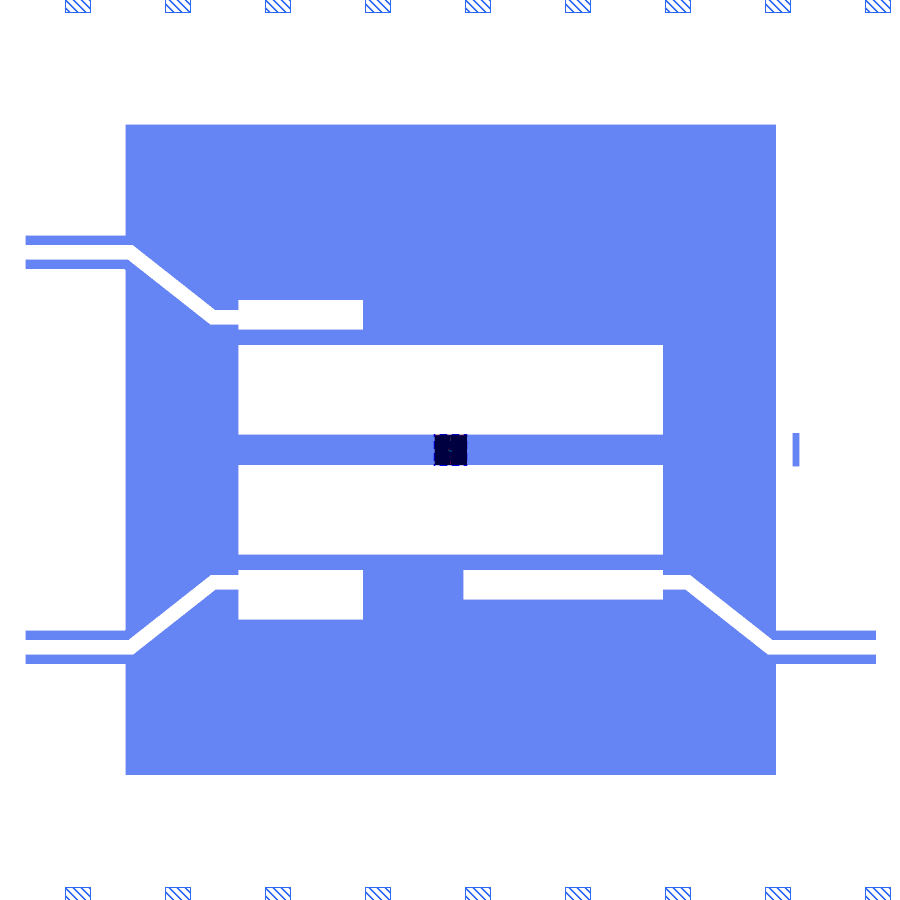

WindowsPath('examples/designs/metal/a5_launch_video_step_parts.png')

In [6]:
# Quantcore trilayer junction on the PDK rule (Nb Δ 1.4 meV): nominal fingers 0.5 × 0.6 µm → R_n 45 kΩ,
# L_J 6.73 nH, C_J 15 fF. JJ_PARAMS = {"junction_type": "Quantcore Junction"}; JUNCTION = its {Lj_nH, Cj_fF}
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
print("junction:", JJ_PARAMS, JUNCTION)
with d.batch():
    pin = dict(cpw_width=15, cpw_gap=9)             # Metal: the design variables cpw_width / cpw_gap
    pads = {"a": {"loc_W": 1, "loc_H": -1, "pad_width": 200, **pin},
            "b": {"loc_W": -1, "loc_H": 1, "pad_height": 30, **pin},
            "c": {"loc_W": -1, "loc_H": -1, "pad_height": 50, **pin}}
    tp = dict(pad_width=425, pocket_height=650, connection_pads=pads, junction=JUNCTION, **JJ_PARAMS)
    q1 = d.add("Q1", "metal:TransmonPocket", at=P(2422.51, 0), rot=0, **tp)
    q2 = d.add("Q2", "metal:TransmonPocket", at=P(0, -950), rot=270, **tp)
    q3 = d.add("Q3", "metal:TransmonPocket", at=P(-2422.51, 0), rot=180, **tp)
    q4 = d.add("Q4", "metal:TransmonPocket", at=P(0, 950), rot=90, **tp)
    otg = {k: d.add(f"OTG{k}", "metal:OpenToGround", at=P(x, y), rot=r, gap=9, width=15)
           for k, x, y, r in ((1, 2771, 0, 180), (2, 0, -1301, 90), (3, -2771, 0, 0), (4, 0, 1301, 270))}
print("Q1 ports:", sorted(q1.ports), "| OTG1 ports:", sorted(otg[1].ports))
qx, qy = P(2422.51, 0)
snap(d, OUT / "a5_launch_video_step_parts.png", box=(qx - 450, qy - 450, qx + 450, qy + 450), size=(900, 900), width=360)

## 6 · Routes: ring buses, charge lines and readouts

- **Ring buses:** four fixed-length λ/2 meanders between neighbouring qubits' `b` / `c` pads (5600 / 5700 µm, the
  15/9 µm CPW), with a 50 µm turn radius so the two meander rows fit in the 400 µm between the pads.
- **Charge lines:** from each `OpenToGround` to its corner launchpad through Metal's `RouteAnchors` anchors.
- **Readouts:** fixed-length λ/2 meanders from each qubit's `a` pad to its coupled launchpad (5500 µm east / west,
  13 000 µm south / north); the waypoints keep them clear of the charge lines. `ol3` / `ol4` are the point mirrors of
  `ol1` / `ol2` through the chip centre, as in the source.
- **Sim groups:** the ring (four qubits and four buses, C-matrix) and each qubit with its readout and launchpad
  (C-matrix and eigenmode); the margins make each box cut every other line once.

route lengths (µm): {'cpw1': 5600, 'cpw2': 5700, 'cpw3': 5600, 'cpw4': 5700, 'line_cl1': 4453, 'line_cl2': 5884, 'line_cl3': 4453, 'line_cl4': 5884, 'ol1': 5500, 'ol2': 13000, 'ol3': 5500, 'ol4': 13000}


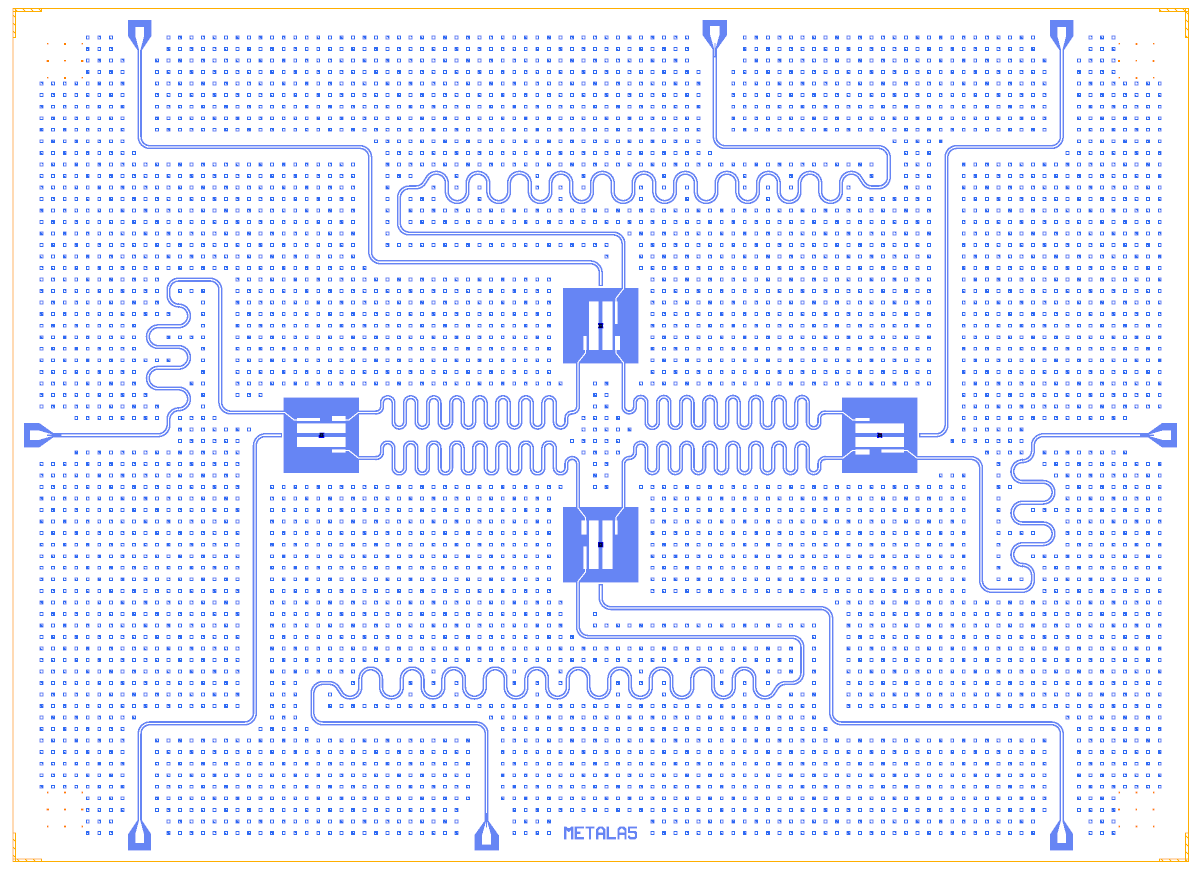

WindowsPath('examples/designs/metal/a5_launch_video_step_routes.png')

In [7]:
with d.batch():
    RB = 50                                      # ring-bus fillet (Metal 90): the two meander rows fit 400 µm apart
    d.route("cpw1", q1.c, q2.b, meander=5600, r=RB, **CPW)
    d.route("cpw2", q3.b, q2.c, meander=5700, r=RB, **CPW)
    d.route("cpw3", q3.c, q4.b, meander=5600, r=RB, **CPW)
    d.route("cpw4", q1.b, q4.c, meander=5700, r=RB, **CPW)
    anchors = {1: [(3000, 0), (3000, 2500), (4000, 2500)], 2: [(0, -1500), (2000, -1500), (2000, -2500), (4000, -2500)],
               3: [(-3000, 0), (-3000, -2500), (-4000, -2500)], 4: [(0, 1500), (-2000, 1500), (-2000, 2500), (-4000, 2500)]}
    for k, an in anchors.items():
        d.route(f"line_cl{k}", otg[k].open, pc[k].tie, r=R, nodes=[P(*a) for a in an], **CPW)
    # readouts: ol1/ol3 down (up) beside the charge lines, ol2/ol4 one long meander under (over) the ring;
    # ol3/ol4 are the point mirrors of ol1/ol2 through the chip centre, as in the source
    M = lambda pts: [(2 * X0 - x, 2 * Y0 - y) for x, y in pts]
    path1 = [(7800, 2802.5), (7800, 1650), (8250, 1650), (8250, 3000)]
    path2 = [(4302.5, 1250), (6250, 1250), (6250, 850), (2000, 850), (2000, 500), (3510, 500)]
    for k, q, L, nodes in ((1, q1, 5500, path1), (2, q2, 13000, path2), (3, q3, 5500, M(path1)), (4, q4, 13000, M(path2))):
        d.route(f"ol{k}", q.a, pq[k].tie, meander=L, r=R, nodes=nodes, **CPW)
# FEM boxes: margins chosen so that each box cuts every other line once (no meander lobes inside)
d.sim_group("ring", ["Q1", "Q2", "Q3", "Q4", "cpw1", "cpw2", "cpw3", "cpw4"], margin_um=150, analyses=["q3d_cmatrix"])
for k in (1, 2, 3, 4):
    d.sim_group(f"Q{k}_read", [f"Q{k}", f"ol{k}", f"P{k}_Q"], margin_um=60, analyses=["q3d_cmatrix", "eigenmode_epr"])
rebuild(d)
print("route lengths (µm):", {k: round(v) for k, v in d.result.route_lengths().items()})
snap(d, OUT / "a5_launch_video_step_routes.png", size=(1200, 870), width=480)

## 7 · Centre the content and save

The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
(components and routes) and shifts the design so its centre is the die centre (pads keep their 100 µm: they slide
back to the edge along it). With pads on all four edges and the point-symmetric ring, nothing should move. Then the
design is saved: the JSON is the deliverable.

In [8]:
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
DESIGN = d.save(OUT / "a5_launch_video.json")
print(d, "→", DESIGN)

content shifted by (0.0, 0.0) µm
<Designer a5_launch_video: 16 instances, 12 routes, live=False> → examples\designs\metal\a5_launch_video.json


## 8 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here: **no errors**; eight `dangling_port` warnings (`squid_a` / `squid_b` of the four qubits, the
junctions' attachment points: the qubit cell draws the junction itself, nothing is routed there); four `overlap`
warnings, each `OpenToGround`'s box touching its qubit's pocket box (the charge-line tip sits 23.5 µm outside the
pocket, as in the source); and **no PDK design warnings** (the pads are at 100 µm, the nominal junction is in the R_n
window, the tutorial states no target).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [9]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 12 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 8 | Q1.squid_a is not connected (no route or snap) |
| warning | `overlap` | 4 | OTG1 and Q1 overlap |

| check | value |
|---|---|
| cheese | the original design's rule (drawn in the build): size 25, gap 75, rows 1000, clearance 25, edge 200 |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 4 |
| PDK design warnings | 0 (none) |

## 9 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: a `TransmonPocket` gives two floating pad nodes with the junction
between them, plus a node per connection pad. Each bus between two pads and each readout between a pad and a coupled
launchpad (series C to its 50 Ω port) is a λ/2 `TLres`. Each charge line joins its 50 Ω launchpad to its open end
(`OTG<k>.end`) with no element to the qubit (see the intro). The port map shows where Q1's ports landed.

In [10]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q1.", "OTG1."))})

**25 nodes · 76 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `OTG1.end` | `P1_C.pad`, `OTG1.end` |
| `OTG2.end` | `P2_C.pad`, `OTG2.end` |
| `OTG3.end` | `P3_C.pad`, `OTG3.end` |
| `OTG4.end` | `P4_C.pad`, `OTG4.end` |
| `P1_Q.pad` | `P1_Q.pad` |
| `P1_Q.tie` | `P1_Q.tie`, `Q1.a` |
| `P2_Q.pad` | `P2_Q.pad` |
| `P2_Q.tie` | `P2_Q.tie`, `Q2.a` |
| `P3_Q.pad` | `P3_Q.pad` |
| `P3_Q.tie` | `P3_Q.tie`, `Q3.a` |
| `P4_Q.pad` | `P4_Q.pad` |
| `P4_Q.tie` | `P4_Q.tie`, `Q4.a` |
| `Q1.island1` | `Q1.island1` |
| `Q1.island2` | `Q1.island2` |
| `Q1.b` | `Q1.b`, `Q4.c` |
| `Q1.c` | `Q1.c`, `Q2.b` |
| `Q2.island1` | `Q2.island1` |
| `Q2.island2` | `Q2.island2` |
| `Q2.c` | `Q2.c`, `Q3.b` |
| `Q3.island1` | `Q3.island1` |
| `Q3.island2` | `Q3.island2` |
| `Q3.c` | `Q3.c`, `Q4.b` |
| `Q4.island1` | `Q4.island1` |
| `Q4.island2` | `Q4.island2` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_P1_C` | R | `OTG1.end` – `gnd` | 50 Ω |
| `Port_P2_C` | R | `OTG2.end` – `gnd` | 50 Ω |
| `Port_P3_C` | R | `OTG3.end` – `gnd` | 50 Ω |
| `Port_P4_C` | R | `OTG4.end` – `gnd` | 50 Ω |
| `Port_P1_Q` | R | `P1_Q.pad` – `gnd` | 50 Ω |
| `Ck_P1_Q` | C | `P1_Q.pad` – `P1_Q.tie` | 11 fF |
| `C_P1_Q_tie` | C | `P1_Q.tie` – `gnd` | 0 fF |
| `Port_P2_Q` | R | `P2_Q.pad` – `gnd` | 50 Ω |
| `Ck_P2_Q` | C | `P2_Q.pad` – `P2_Q.tie` | 11 fF |
| `C_P2_Q_tie` | C | `P2_Q.tie` – `gnd` | 0 fF |
| `Port_P3_Q` | R | `P3_Q.pad` – `gnd` | 50 Ω |
| `Ck_P3_Q` | C | `P3_Q.pad` – `P3_Q.tie` | 11 fF |
| `C_P3_Q_tie` | C | `P3_Q.tie` – `gnd` | 0 fF |
| `Port_P4_Q` | R | `P4_Q.pad` – `gnd` | 50 Ω |
| `Ck_P4_Q` | C | `P4_Q.pad` – `P4_Q.tie` | 11 fF |
| `C_P4_Q_tie` | C | `P4_Q.tie` – `gnd` | 0 fF |
| `C_Q1_1` | C | `Q1.island1` – `gnd` | 34.3 fF |
| `C_Q1_2` | C | `Q1.island2` – `gnd` | 34.3 fF |
| `C_Q1_12` | C | `Q1.island1` – `Q1.island2` | 26.2 fF |
| `J_Q1` | JJ | `Q1.island1` – `Q1.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q1_a` | C | `Q1.island2` – `P1_Q.tie` | 24.8 fF |
| `Cf_Q1_a` | C | `Q1.island1` – `P1_Q.tie` | 2.6 fF |
| `Cc_Q1_a` | C | `P1_Q.tie` – `gnd` | 38.4 fF |
| `Cg_Q1_b` | C | `Q1.island1` – `Q1.b` | 17 fF |
| `Cf_Q1_b` | C | `Q1.island2` – `Q1.b` | 1.8 fF |
| `Cc_Q1_b` | C | `Q1.b` – `gnd` | 35.2 fF |
| `Cg_Q1_c` | C | `Q1.island2` – `Q1.c` | 16.8 fF |
| `Cf_Q1_c` | C | `Q1.island1` – `Q1.c` | 1.8 fF |
| `Cc_Q1_c` | C | `Q1.c` – `gnd` | 38.6 fF |
| `C_Q2_1` | C | `Q2.island1` – `gnd` | 34.3 fF |
| `C_Q2_2` | C | `Q2.island2` – `gnd` | 34.3 fF |
| `C_Q2_12` | C | `Q2.island1` – `Q2.island2` | 26.2 fF |
| `J_Q2` | JJ | `Q2.island1` – `Q2.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q2_a` | C | `Q2.island2` – `P2_Q.tie` | 24.8 fF |
| `Cf_Q2_a` | C | `Q2.island1` – `P2_Q.tie` | 2.6 fF |
| `Cc_Q2_a` | C | `P2_Q.tie` – `gnd` | 38.4 fF |
| `Cg_Q2_b` | C | `Q2.island1` – `Q1.c` | 17 fF |
| `Cf_Q2_b` | C | `Q2.island2` – `Q1.c` | 1.8 fF |
| `Cc_Q2_b` | C | `Q1.c` – `gnd` | 35.2 fF |
| `Cg_Q2_c` | C | `Q2.island2` – `Q2.c` | 16.8 fF |
| `Cf_Q2_c` | C | `Q2.island1` – `Q2.c` | 1.8 fF |
| `Cc_Q2_c` | C | `Q2.c` – `gnd` | 38.6 fF |
| `C_Q3_1` | C | `Q3.island1` – `gnd` | 34.3 fF |
| `C_Q3_2` | C | `Q3.island2` – `gnd` | 34.3 fF |
| `C_Q3_12` | C | `Q3.island1` – `Q3.island2` | 26.2 fF |
| `J_Q3` | JJ | `Q3.island1` – `Q3.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q3_a` | C | `Q3.island2` – `P3_Q.tie` | 24.8 fF |
| `Cf_Q3_a` | C | `Q3.island1` – `P3_Q.tie` | 2.6 fF |
| `Cc_Q3_a` | C | `P3_Q.tie` – `gnd` | 38.4 fF |
| `Cg_Q3_b` | C | `Q3.island1` – `Q2.c` | 17 fF |
| `Cf_Q3_b` | C | `Q3.island2` – `Q2.c` | 1.8 fF |
| `Cc_Q3_b` | C | `Q2.c` – `gnd` | 35.2 fF |
| `Cg_Q3_c` | C | `Q3.island2` – `Q3.c` | 16.8 fF |
| `Cf_Q3_c` | C | `Q3.island1` – `Q3.c` | 1.8 fF |
| `Cc_Q3_c` | C | `Q3.c` – `gnd` | 38.6 fF |
| `C_Q4_1` | C | `Q4.island1` – `gnd` | 34.3 fF |
| `C_Q4_2` | C | `Q4.island2` – `gnd` | 34.3 fF |
| `C_Q4_12` | C | `Q4.island1` – `Q4.island2` | 26.2 fF |
| `J_Q4` | JJ | `Q4.island1` – `Q4.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q4_a` | C | `Q4.island2` – `P4_Q.tie` | 24.8 fF |
| `Cf_Q4_a` | C | `Q4.island1` – `P4_Q.tie` | 2.6 fF |
| `Cc_Q4_a` | C | `P4_Q.tie` – `gnd` | 38.4 fF |
| `Cg_Q4_b` | C | `Q4.island1` – `Q3.c` | 17 fF |
| `Cf_Q4_b` | C | `Q4.island2` – `Q3.c` | 1.8 fF |
| `Cc_Q4_b` | C | `Q3.c` – `gnd` | 35.2 fF |
| `Cg_Q4_c` | C | `Q4.island2` – `Q1.b` | 16.8 fF |
| `Cf_Q4_c` | C | `Q4.island1` – `Q1.b` | 1.8 fF |
| `Cc_Q4_c` | C | `Q1.b` – `gnd` | 38.6 fF |
| `cpw1` | TLres | `Q1.c` – `gnd` | lambda/2, 5600 µm, 11.259 GHz |
| `cpw2` | TLres | `Q2.c` – `gnd` | lambda/2, 5700 µm, 11.062 GHz |
| `cpw3` | TLres | `Q3.c` – `gnd` | lambda/2, 5600 µm, 11.259 GHz |
| `cpw4` | TLres | `Q1.b` – `gnd` | lambda/2, 5700 µm, 11.062 GHz |
| `ol1` | TLres | `P1_Q.tie` – `gnd` | lambda/2, 5500 µm, 11.464 GHz |
| `ol2` | TLres | `P2_Q.tie` – `gnd` | lambda/2, 13000 µm, 4.850 GHz |
| `ol3` | TLres | `P3_Q.tie` – `gnd` | lambda/2, 5500 µm, 11.464 GHz |
| `ol4` | TLres | `P4_Q.tie` – `gnd` | lambda/2, 13000 µm, 4.850 GHz |

**Unconnected ports:** none

{'Q1.squid_a': 'Q1.island2', 'Q1.squid_b': 'Q1.island1', 'Q1.a': 'P1_Q.tie', 'Q1.b': 'Q1.b', 'Q1.c': 'Q1.c', 'OTG1.open': 'OTG1.end'}


## 10 · LOM simulation

Each qubit with its readout and launchpad; then each ring bus with the two qubits it joins (QuCat normal modes,
static ZZ from QuTiP). With the PDK nominal junction the qubits sit near 7.0 GHz (the 10 nH assumed before the
rebuild gave 6.2 GHz); loaded, the 5.5 mm readouts and the buses sit above them and the 13 mm readouts below. The
bus-coupled pairs are detuned by the `b` / `c` pad sizes, so their ZZ is defined. The tutorial states no targets.

In [11]:
results = simulate_groups(d, {f"Q{k}+ol{k}": [f"Q{k}", f"ol{k}", f"P{k}_Q"] for k in (1, 2, 3, 4)})
display(Markdown(groups_md(results)))
ring = {"Q1+cpw1+Q2": ["Q1", "cpw1", "Q2"], "Q3+cpw2+Q2": ["Q3", "cpw2", "Q2"],
        "Q3+cpw3+Q4": ["Q3", "cpw3", "Q4"], "Q1+cpw4+Q4": ["Q1", "cpw4", "Q4"]}
coupled = simulate_groups(d, ring, max_modes=3)
for g, res in coupled.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(res)))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(coupled)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1+ol1 | Q1 | 6.9668 | -296.7 | ol1 | 10.588 | 9.07 | -2.48 |
| Q2+ol2 | Q2 | 6.9791 | -298.3 | ol2 | 4.6763 | 0.818 | -0.69 |
| Q3+ol3 | Q3 | 6.9668 | -296.7 | ol3 | 10.588 | 9.07 | -2.48 |
| Q4+ol4 | Q4 | 6.9791 | -298.3 | ol4 | 4.6763 | 0.818 | -0.69 |

**Q1+cpw1+Q2, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q2 | qubit | 7.2419 | 0 | 256.9 | J_Q2 0.98, J_Q1 0.02 |
| Q1 | qubit | 7.2802 | 0 | 261.0 | J_Q1 0.98, J_Q2 0.02 |
| cpw1 | resonator | 10.0653 | 0 | 0.0 | cpw1 0.99 |

**Q3+cpw2+Q2, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q3 | qubit | 7.2414 | 0 | 255.6 | J_Q3 0.97, J_Q2 0.02 |
| Q2 | qubit | 7.2801 | 0 | 259.9 | J_Q2 0.98, J_Q3 0.02 |
| cpw2 | resonator | 9.9073 | 0 | 0.0 | cpw2 0.99 |

**Q3+cpw3+Q4, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q4 | qubit | 7.2419 | 0 | 256.9 | J_Q4 0.98, J_Q3 0.02 |
| Q3 | qubit | 7.2802 | 0 | 261.0 | J_Q3 0.98, J_Q4 0.02 |
| cpw3 | resonator | 10.0653 | 0 | 0.0 | cpw3 0.99 |

**Q1+cpw4+Q4, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q1 | qubit | 7.2414 | 0 | 255.6 | J_Q1 0.97, J_Q4 0.02 |
| Q4 | qubit | 7.2801 | 0 | 259.9 | J_Q4 0.98, J_Q1 0.02 |
| cpw4 | resonator | 9.9073 | 0 | 0.0 | cpw4 0.99 |

**Static ZZ (QuTiP):**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| Q1+cpw1+Q2 | Q1-Q2 | 214.9 | yes | no |
| Q3+cpw2+Q2 | Q2-Q3 | 235.1 | yes | no |
| Q3+cpw3+Q4 | Q3-Q4 | 214.9 | yes | no |
| Q1+cpw4+Q4 | Q1-Q4 | 235.1 | yes | no |

## 11 · FEM: send the job

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

A **Q3D C-matrix** job for the ring (four qubits with the four buses: the core the tutorial's second video
renders) and, per qubit, a C-matrix and an **eigenmode / EPR** job with its readout and launchpad (lines leaving the
box end in 50 Ω, so the mode Q gives κ).

`RUN_FEM = False` keeps the notebook fast. Set it to `True` to solve the jobs here: `send_fem_jobs` finds AEDT 2024
R1 (or newer) and solves each Ansys job in a **new batch, non-graphical** AEDT, so an AEDT window you have open is
never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [12]:
jobs = export_sims(DESIGN)
jobs_eig = export_sims(DESIGN, [f"Q{k}_read" for k in (1, 2, 3, 4)], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| ring | `build/jobs/a5_launch_video_ring_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · junction · `Q2.junction`<br>3 · junction · `Q3.junction`<br>4 · junction · `Q4.junction`<br>5 · waveguide · `Q1.c`<br>6 · waveguide · `Q2.b`<br>7 · waveguide · `Q3.b`<br>8 · waveguide · `Q2.c`<br>9 · waveguide · `Q3.c`<br>10 · waveguide · `Q4.b`<br>11 · waveguide · `Q1.b`<br>12 · waveguide · `Q4.c`<br>13 · edge · `line_cl1`<br>14 · edge · `line_cl2`<br>15 · edge · `line_cl3`<br>16 · edge · `line_cl4`<br>17 · edge · `ol1`<br>18 · edge · `ol2`<br>19 · edge · `ol3`<br>20 · edge · `ol4` | `Q1.island2`, `Q2.island2`, `Q3.island2`, `Q4.island2`, `Q1.c`, `Q2.b`, `Q3.b`, `Q2.c`, `Q3.c`, `Q4.b`, `Q1.b`, `Q4.c`, `line_cl1`, `line_cl2`, `line_cl3`, `line_cl4`, `ol1`, `ol2`, `ol3`, `ol4`, `Q2.island1`, `Q3.island1`, `Q1.island1`, `Q4.island1` |
| Q1_read | `build/jobs/a5_launch_video_Q1_read_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · waveguide · `Q1.a`<br>3 · waveguide · `P1_Q.tie`<br>4 · edge · `cpw1`<br>5 · edge · `cpw4`<br>6 · edge · `line_cl1`<br>7 · lumped · `P1_Q.pad` | `Q1.island2`, `Q1.a`, `P1_Q.tie`, `cpw1`, `cpw4`, `line_cl1`, `P1_Q.pad`, `Q1.island1` |
| Q2_read | `build/jobs/a5_launch_video_Q2_read_q3d_cmatrix` | 1 · junction · `Q2.junction`<br>2 · waveguide · `Q2.a`<br>3 · waveguide · `P2_Q.tie`<br>4 · edge · `cpw1`<br>5 · edge · `cpw2`<br>6 · edge · `line_cl2`<br>7 · lumped · `P2_Q.pad` | `Q2.island2`, `Q2.a`, `P2_Q.tie`, `cpw1`, `cpw2`, `line_cl2`, `P2_Q.pad`, `Q2.island1` |
| Q3_read | `build/jobs/a5_launch_video_Q3_read_q3d_cmatrix` | 1 · junction · `Q3.junction`<br>2 · waveguide · `Q3.a`<br>3 · waveguide · `P3_Q.tie`<br>4 · edge · `cpw2`<br>5 · edge · `cpw3`<br>6 · edge · `line_cl3`<br>7 · lumped · `P3_Q.pad` | `Q3.island2`, `Q3.a`, `P3_Q.tie`, `cpw2`, `cpw3`, `line_cl3`, `P3_Q.pad`, `Q3.island1` |
| Q4_read | `build/jobs/a5_launch_video_Q4_read_q3d_cmatrix` | 1 · junction · `Q4.junction`<br>2 · waveguide · `Q4.a`<br>3 · waveguide · `P4_Q.tie`<br>4 · edge · `cpw3`<br>5 · edge · `cpw4`<br>6 · edge · `line_cl4`<br>7 · lumped · `P4_Q.pad` | `Q4.island2`, `Q4.a`, `P4_Q.tie`, `cpw3`, `cpw4`, `line_cl4`, `P4_Q.pad`, `Q4.island1` |
| Q1_read | `build/jobs/a5_launch_video_Q1_read_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · edge_lumped · `cpw1`<br>3 · edge_lumped · `cpw4`<br>4 · edge_lumped · `line_cl1`<br>5 · lumped · `P1_Q.pad` | `Q1.island2`, `cpw1`, `cpw4`, `line_cl1`, `P1_Q.pad`, `Q1.a`, `Q1.island1` |
| Q2_read | `build/jobs/a5_launch_video_Q2_read_eigenmode_epr` | 1 · junction · `Q2.junction`<br>2 · edge_lumped · `cpw1`<br>3 · edge_lumped · `cpw2`<br>4 · edge_lumped · `line_cl2`<br>5 · lumped · `P2_Q.pad` | `Q2.island2`, `cpw1`, `cpw2`, `line_cl2`, `P2_Q.pad`, `Q2.a`, `Q2.island1` |
| Q3_read | `build/jobs/a5_launch_video_Q3_read_eigenmode_epr` | 1 · junction · `Q3.junction`<br>2 · edge_lumped · `cpw2`<br>3 · edge_lumped · `cpw3`<br>4 · edge_lumped · `line_cl3`<br>5 · lumped · `P3_Q.pad` | `Q3.island2`, `cpw2`, `cpw3`, `line_cl3`, `P3_Q.pad`, `Q3.island1`, `Q3.a` |
| Q4_read | `build/jobs/a5_launch_video_Q4_read_eigenmode_epr` | 1 · junction · `Q4.junction`<br>2 · edge_lumped · `cpw3`<br>3 · edge_lumped · `cpw4`<br>4 · edge_lumped · `line_cl4`<br>5 · lumped · `P4_Q.pad` | `Q4.island2`, `cpw3`, `cpw4`, `line_cl4`, `P4_Q.pad`, `Q4.island1`, `Q4.a` |

In [13]:
RUN_FEM = False   # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
if RUN_FEM:
    send_fem_jobs(DESIGN, ['ring', 'Q1_read', 'Q2_read', 'Q3_read', 'Q4_read'], run=True)

## 12 · Bring the FEM results back

When a job has been solved, its folder holds `results/results.json`. `fem_back` fills the LOM with the extracted
C-matrix (matched by net name: the job's nets are the LOM's nodes) and lists each capacitance as estimate vs
extracted. Without results it says what would appear; the LOM values above stay the estimates.

In [14]:
filled, back_md = fem_back(lb.model, DESIGN, {**{f"{g} · q3d": v for g, v in jobs.items()}, **{f"{g} · eigenmode": v for g, v in jobs_eig.items()}})
display(Markdown(back_md))
for key, fc in filled.items():                   # re-simulate the LOM on the extracted values
    display(Markdown(f"**{key}, LOM on the FEM values:**"))
    display(Markdown(modes_md(simulate(fc))))

No FEM results yet for ring · q3d, Q1_read · q3d, Q2_read · q3d, Q3_read · q3d, Q4_read · q3d, Q1_read · eigenmode, Q2_read · eigenmode, Q3_read · eigenmode, Q4_read · eigenmode: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 13 · Iterate: change one property and re-simulate

A design loop in one cell: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here the ring bus `cpw1` between Q1 and Q2, 5600 → 5400 µm — rebuild, re-run the LOM of
that bus with its two qubits and compare. A shorter λ/2 bus resonates higher (f ∝ 1/ℓ, about +3 %); the bus already
sits above the qubits (≈ 10 GHz against 7 GHz), so it moves further away: the dispersive shift and the bus-mediated
static ZZ shrink.

In [15]:
d2 = design_copy(DESIGN)
d2["cpw1"].set(length=5400)                      # 5600 → 5400 µm
after = simulate_groups(d2, {"Q1+cpw1+Q2": ring["Q1+cpw1+Q2"]}, max_modes=3)
display(Markdown(params_delta_md({"Q1+cpw1+Q2": coupled["Q1+cpw1+Q2"]}, after)))
display(Markdown("**Static ZZ after the change:**\n\n" + zz_md(after)))

| parameter | before | after | Δ |
|---|---|---|---|
| `Q1+cpw1+Q2: Q2.f_q_GHz` | 6.9613 | 6.9619 | +0.0006189 |
| `Q1+cpw1+Q2: Q2.alpha_MHz` | -295.01 | -295.44 | -0.4372 |
| `Q1+cpw1+Q2: cpw1.chi_MHz` | -2.5583 | -2.3034 | +0.255 |
| `Q1+cpw1+Q2: Q1.f_q_GHz` | 6.996 | 6.9962 | +0.0002009 |
| `Q1+cpw1+Q2: Q1.alpha_MHz` | -301.24 | -301.18 | +0.05657 |
| `Q1+cpw1+Q2: cpw1.f_GHz` | 10.063 | 10.395 | +0.3324 |
| `Q1+cpw1+Q2: cpw1.kappa_MHz` | 0 | 0 | +0 |

**Static ZZ after the change:**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| Q1+cpw1+Q2 | Q1-Q2 | 180.3 | yes | no |

## 14 · Build and export

The design JSON saved in step 7 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese: the original wins.** The A.5 notebook exports its GDS with Metal's `QGDSRenderer` at its defaults, and the cheese is on by default (`cheese.view_in_file = {main: {1: True}}`: `cheese_0_x/y` 25 µm squares every `delta_x/y` 100 µm, `edge_nocheese` 200 µm, `no_cheese.buffer` 25 µm). So the original *has* cheese, and the precedence rule keeps the original's, not the PDK band. The chip carries Metal's rule as its `cheese` parameter (step 3: `metal_cheese_rule()` = `{size, gap, rows, clearance, edge}`), so the build draws it into KQC's `ground_grid` layer over the whole free ground inside the frame's design area, clear of the 3/0 keep-outs by the buffer (the 3/0 keep-out already adds the PDK route margin round each CPW, so the holes sit a few µm further from the etch than in Metal). The layout, the snapshots and KLive show it, and `export_fab` / `qcc mask` keep it (`cheese source: build`, no PDK band added).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [16]:
print("design file:", DESIGN)
CHEESE = True                                    # export_fab keeps the build's cheese (the original's rule)
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

design file: examples\designs\metal\a5_launch_video.json


| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 5202 |
| 2/0 | JJ_STRAIGHT | 4 |
| 3/0 | M3 | 5192 |
| 4/0 | JJ_BENT | 4 |
| 50/0 | HSQ | 8 |
| 51/0 | SPACER_1 | 8 |
| 52/0 | SPACER_2 | 8 |
| 53/0 | SPACER_3 | 8 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 5190 holes on the mask.

→ `build/a5_launch_video_fab.oas`

## 15 · Snapshots

The full chip (compare the tutorial's screenshot: same components and pins, different meander footprints); `Q1` with
its three connection pads and the charge-line tip; its trilayer junction; the east coupled launchpad where `ol1`
ends (now 100 µm from the edge); the **fab mask** round `Q1` (1/0 etch with the original's Metal cheese, the 3/0
keep-out, the junction layers); and the die frame's south-west corner (dicing L on 1000/0, alignment grid on
1001/0). Positions are read from the design (after the centring shift).

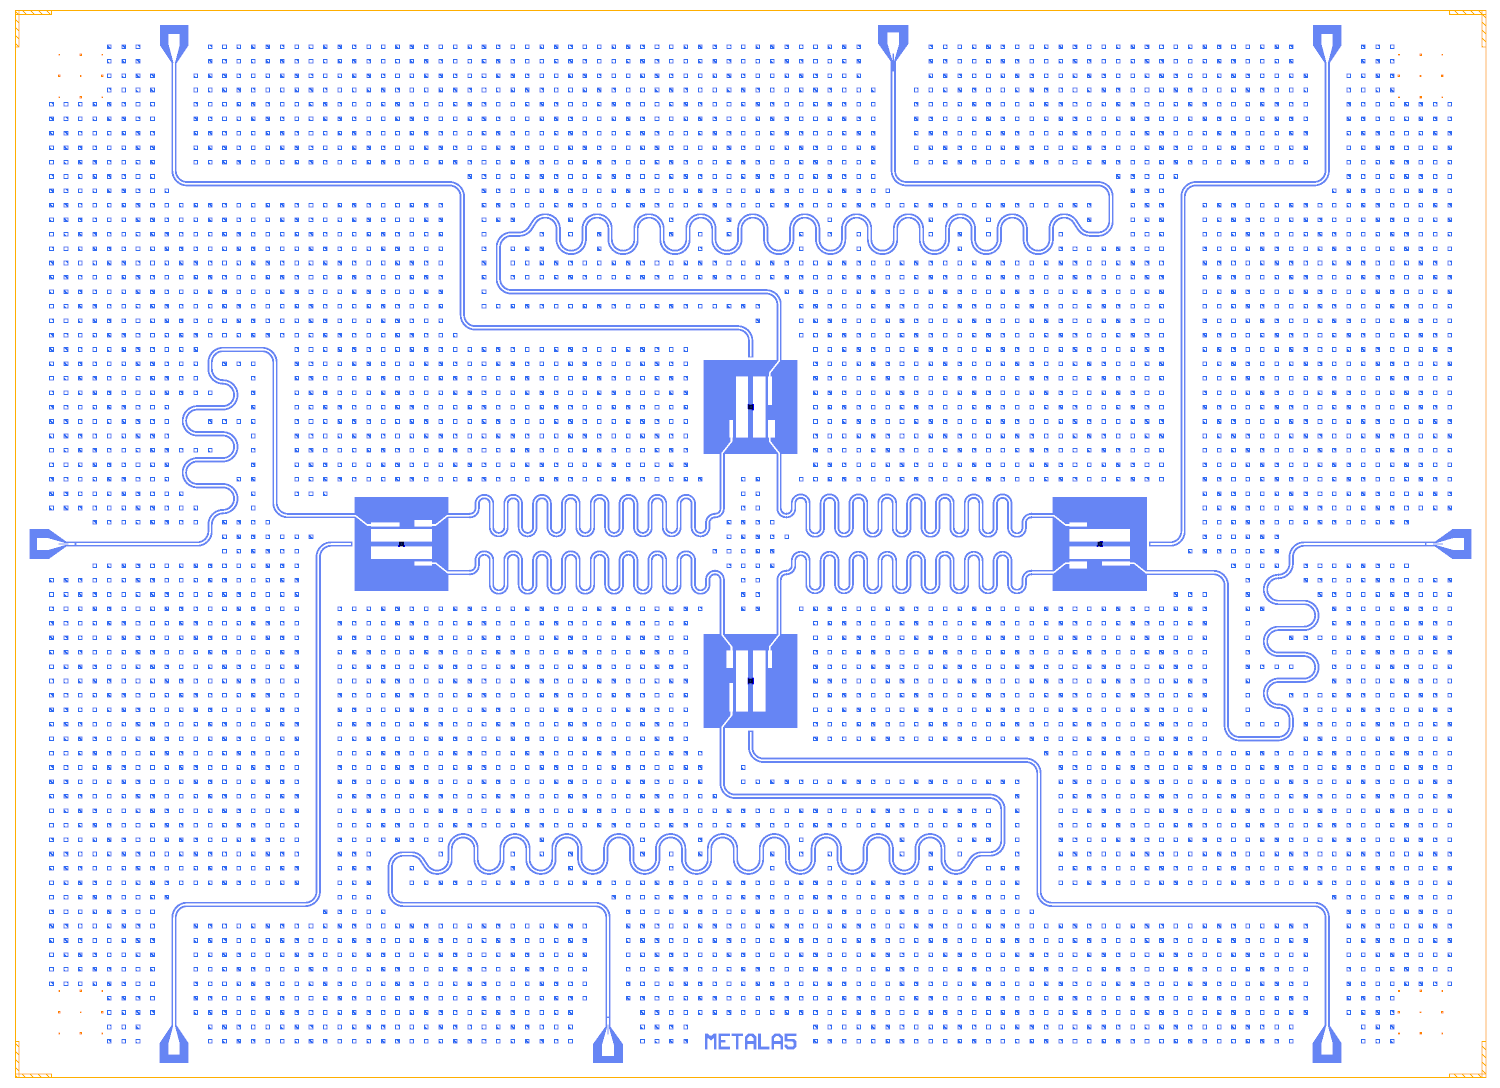

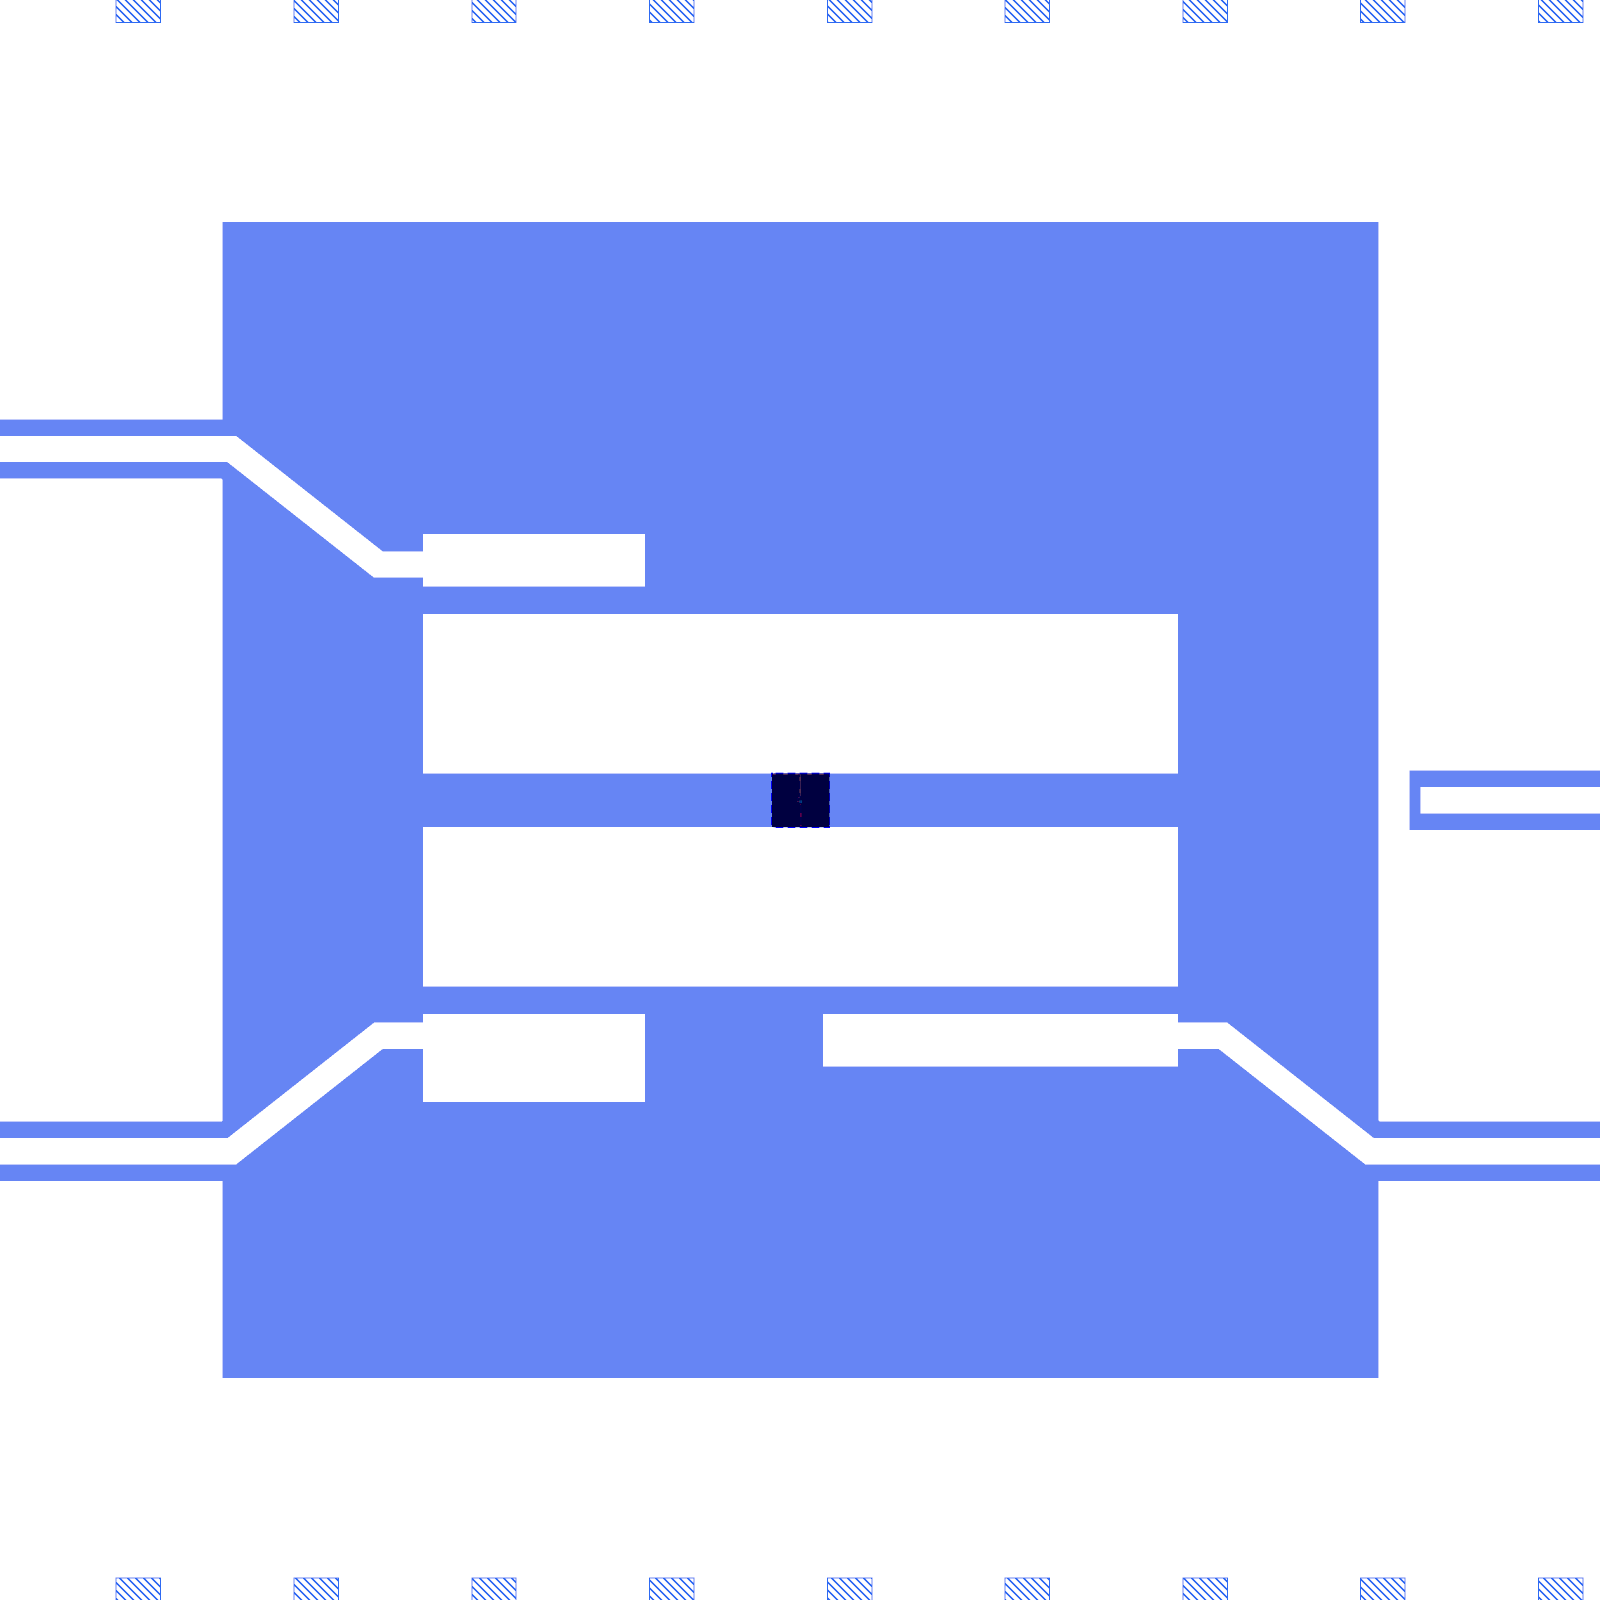

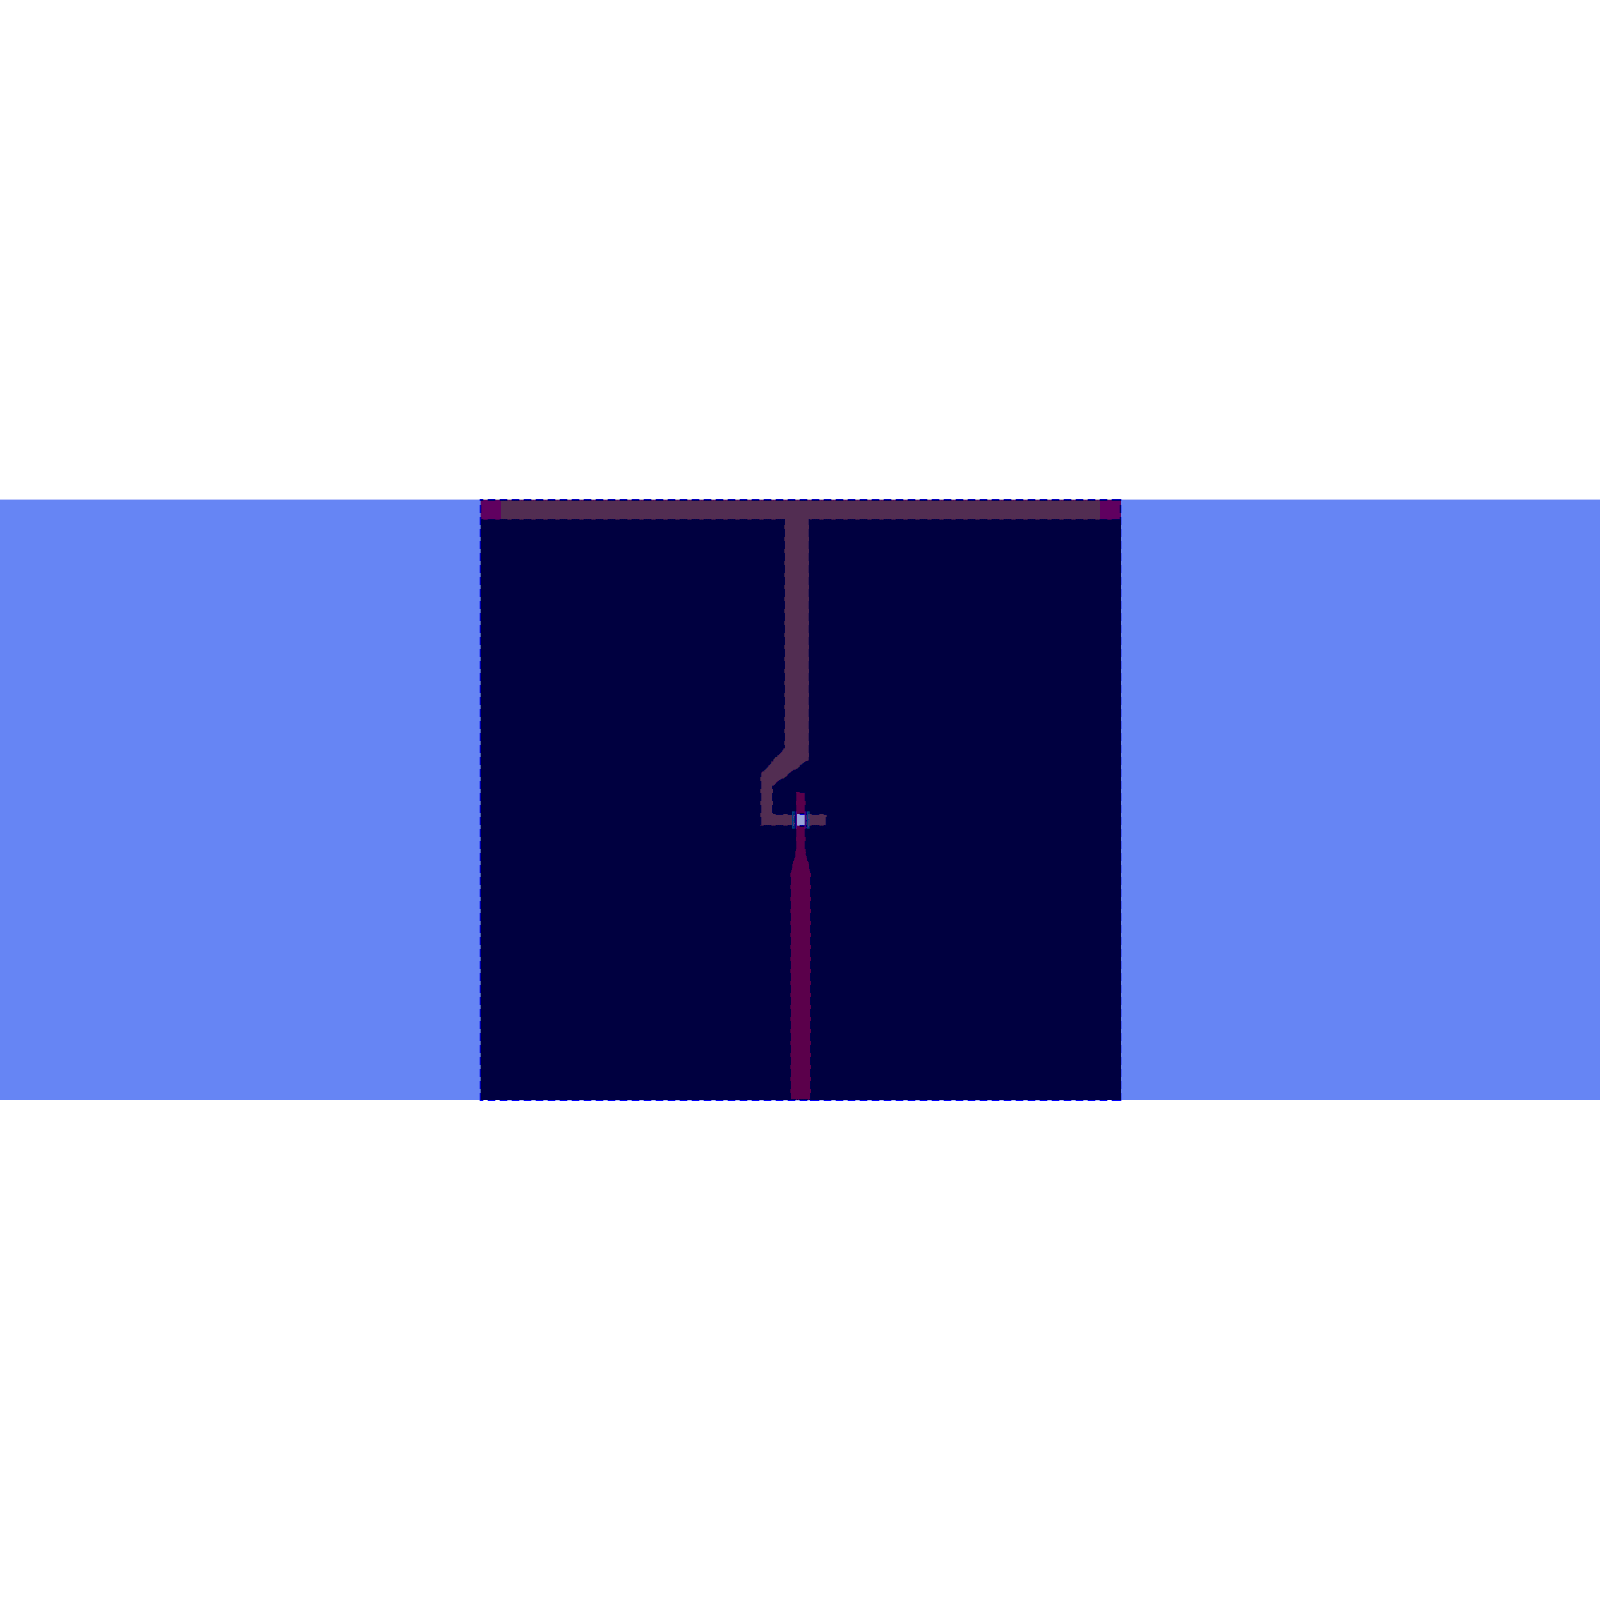

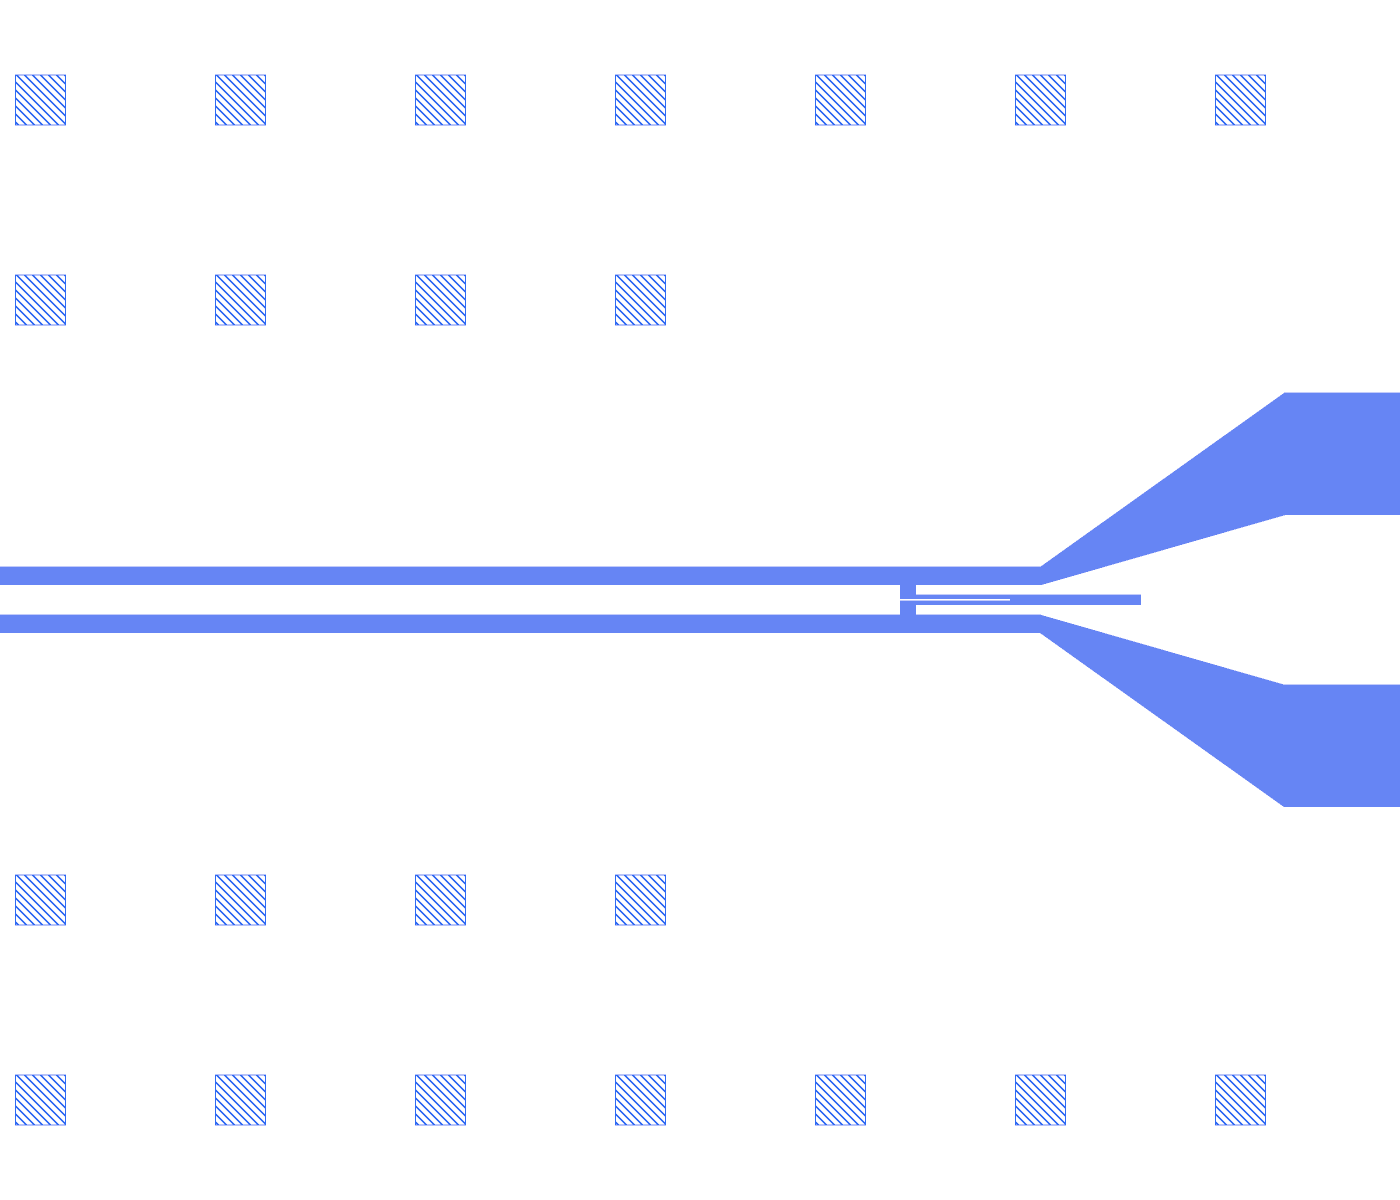

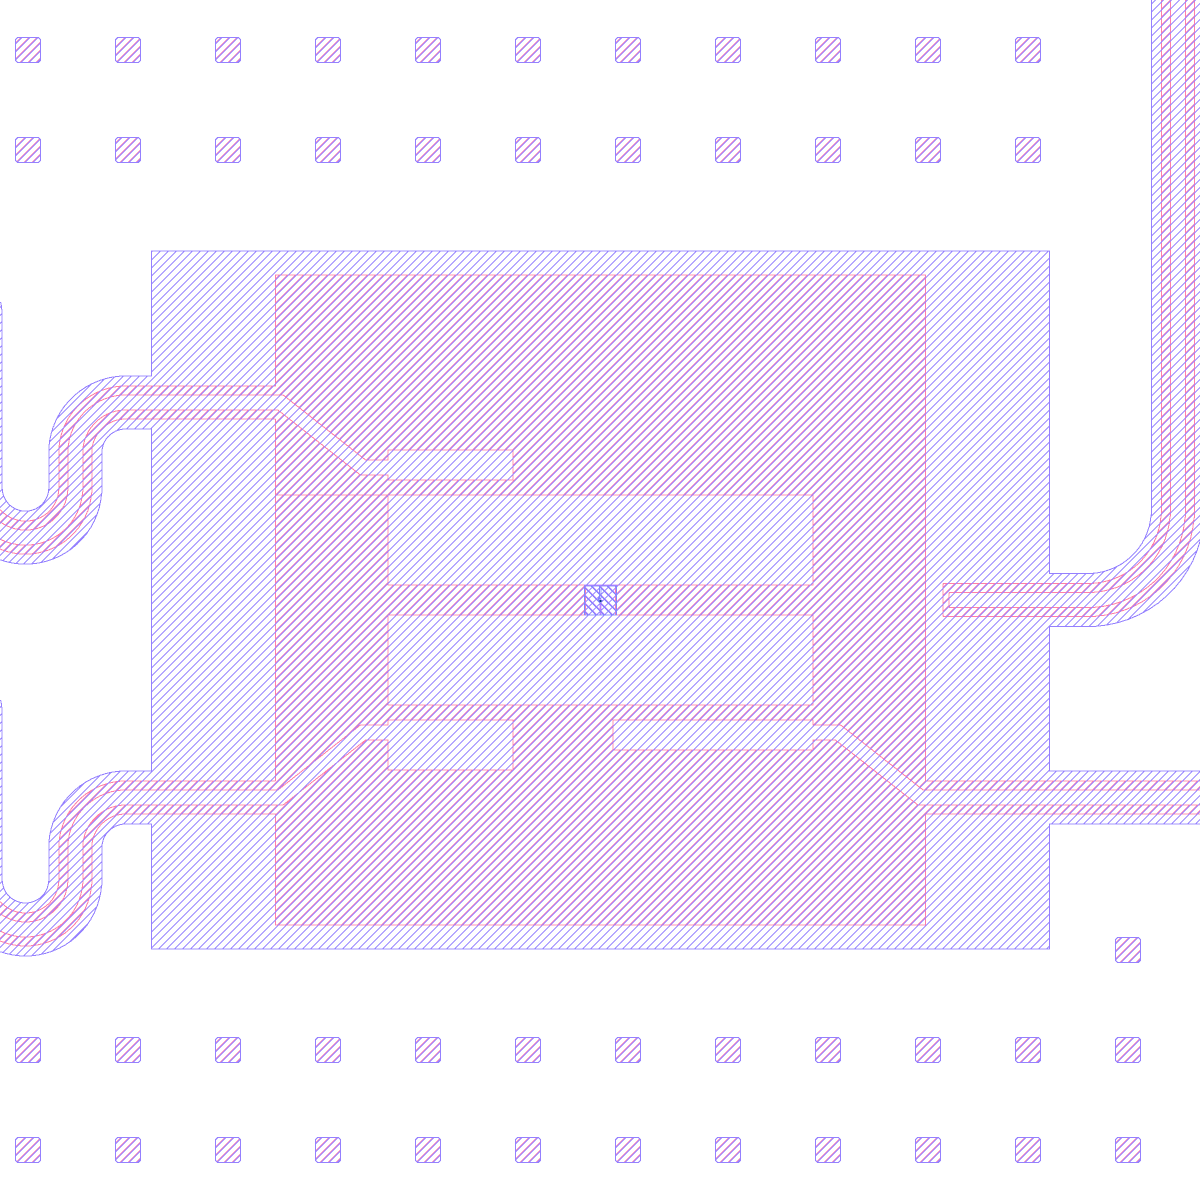

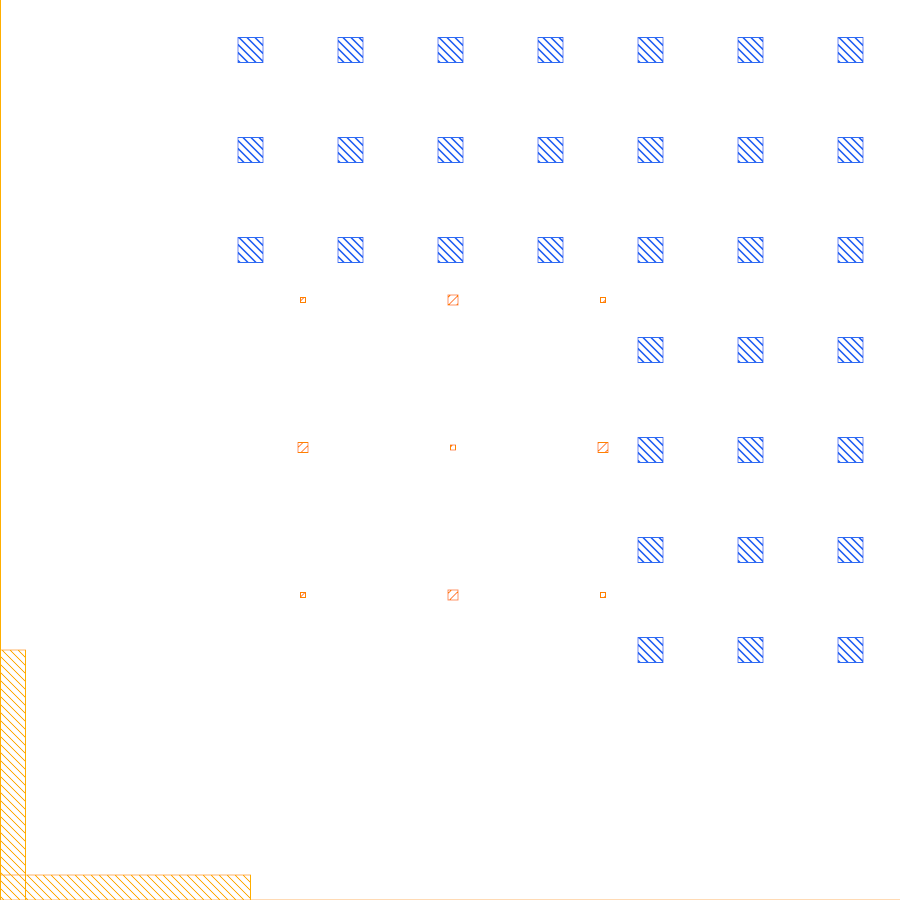

In [17]:
QX, QY = d.data["instances"]["Q1"]["place"]["at"]
show_snapshot(d, OUT / "a5_launch_video.png", size=(1500, 1088))
show_snapshot(d, OUT / "a5_launch_video_q1.png", box=(QX - 450, QY - 450, QX + 450, QY + 450), width=420)
show_snapshot(d, OUT / "a5_launch_video_jj.png", box=(QX - 40, QY - 40, QX + 40, QY + 40), width=300)
px, py = port_xy(d, "P1_Q.tie")
show_snapshot(d, OUT / "a5_launch_video_pad.png", box=(px - 450, py - 300, px + 250, py + 300), size=(1400, 1200), width=360)
snap_file(Path("build") / "a5_launch_video_fab.oas", OUT / "a5_launch_video_cheese.png",
          box=(QX - 600, QY - 600, QX + 600, QY + 600), size=(1200, 1200), width=420)
show_snapshot(d, OUT / "a5_launch_video_frame.png", box=(-600, -700, 300, 200), size=(900, 900), width=300);

## 16 · Summary

| | |
|---|---|
| matches the source | every Metal component and option, their positions and orientations, the route end pins and lengths (buses 5600 / 5700 µm, readouts 5500 / 13 000 µm), the charge lines through Metal's anchors, the sim groups |
| PDK changes | QCT frame on the grown 10.2 × 7.4 mm box; sapphire stack; the eight launchpads 100 µm from the edges (were 628–830 µm); trilayer junctions (PDK nominal); cheese = the original's Metal cheese, drawn by the build; content centred (shift printed in step 7) |
| differs | the meander footprints (qcc router; ring buses with a 50 µm turn radius); LOM f_q 6.97 / 6.98 GHz (α ≈ −297 MHz), readouts 10.59 GHz (5.5 mm; κ 9.1 MHz, χ −2.5 MHz) and 4.68 GHz (13 mm; κ 0.82 MHz, χ −0.69 MHz), buses 9.9–10.1 GHz, static ZZ 215 / 235 kHz per bus pair (the 10 nH assumed before the rebuild gave 6.2 GHz qubits) |
| PDK design warnings | none |
| open | the FEM jobs are exported, not solved (`RUN_FEM = False`) |